# NSL Sign Language Transformer: Colab Training

Run the cells top to bottom. Before starting: **Runtime > Change runtime type > T4 GPU**.

Only edit the config cell (cell 3). Checkpoints are saved straight to Google Drive, so a disconnect won't lose your best model.

In [1]:
import torch
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA available: True
GPU: Tesla T4


In [13]:
# ===== CONFIG: edit these =====
from google.colab import drive
drive.mount('/content/drive')

ZIP_PATH = "/content/drive/MyDrive/Colab Notebooks/Major Project/final_dataset.zip"   # path to your dataset zip in Drive
OUT_DIR  = "/content/drive/MyDrive/Major Project/colab_output"        # checkpoints and history go here

USE_AUG_FILES = True   # False = skip pre-generated aug_*.npy in train, balance with a weighted sampler
                        # True  = include them (to compare against originals-only)

FIXED_LEN   = 100
FEAT_DIM    = 291
BATCH_SIZE  = 32
EPOCHS      = 180
LR          = 0.0001
NUM_CLASSES = 52
PATIENCE    = 15
SEED        = 42

import os
os.makedirs(OUT_DIR, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [14]:
# Unzip to local Colab disk (much faster than reading from Drive) and locate the splits
import os, zipfile, glob

EXTRACT_DIR = "/content/data"
if not os.path.isdir(EXTRACT_DIR):
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(EXTRACT_DIR)

# Find the folder that contains train/ val/ test/
DATA_PATH = None
for root, dirs, _ in os.walk(EXTRACT_DIR):
    if {"train", "val", "test"}.issubset(dirs):
        DATA_PATH = root
        break
assert DATA_PATH, "Could not find a folder containing train/val/test inside the zip"
print("Dataset root:", DATA_PATH)

for split in ("train", "val", "test"):
    n = len(glob.glob(os.path.join(DATA_PATH, split, "*", "*.npy")))
    print(f"  {split}: {n} .npy files")

n_aug = len(glob.glob(os.path.join(DATA_PATH, "train", "*", "aug_*.npy")))
print(f"  of which aug_ files in train: {n_aug}")

Dataset root: /content/data/final_dataset
  train: 9464 .npy files
  val: 2028 .npy files
  test: 2028 .npy files
  of which aug_ files in train: 4251


In [15]:
# Class mapping: use the json from the zip if present, otherwise derive it (sorted class folders, same as combine_datasets.py)
import json

found = glob.glob(os.path.join(EXTRACT_DIR, "**", "class_mapping.json"), recursive=True)
if found:
    with open(found[0], encoding="utf-8") as f:
        sign_to_idx = json.load(f)
    print("Loaded class mapping:", found[0])
else:
    classes = sorted(d for d in os.listdir(os.path.join(DATA_PATH, "train"))
                     if os.path.isdir(os.path.join(DATA_PATH, "train", d)))
    sign_to_idx = {name: i for i, name in enumerate(classes)}
    print("class_mapping.json not in zip, derived from train folders")

assert len(sign_to_idx) == NUM_CLASSES, f"Expected {NUM_CLASSES} classes, got {len(sign_to_idx)}"
idx_to_sign = {v: k for k, v in sign_to_idx.items()}

# Keep a copy next to the checkpoint so predictor.py uses the same mapping
with open(os.path.join(OUT_DIR, "class_mapping.json"), "w", encoding="utf-8") as f:
    json.dump(sign_to_idx, f, indent=2)

class_mapping.json not in zip, derived from train folders


In [23]:
# Model definition (same architecture as src/training/model.py)
import math
import torch
import torch.nn as nn

class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=100, dropout=0.1):
        super().__init__()
        self.dropout = nn.Dropout(dropout)
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len).unsqueeze(1).float()
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return self.dropout(x + self.pe[:, :x.size(1), :])


class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, num_heads, dropout=0.1):
        super().__init__()
        assert d_model % num_heads == 0
        self.d_model, self.num_heads = d_model, num_heads
        self.d_k = d_model // num_heads
        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)
        self.dropout = nn.Dropout(dropout)

    def attention(self, Q, K, V, mask=None):
        scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(self.d_k)
        if mask is not None:
            scores = scores.masked_fill(mask, float("-inf"))
        scores = torch.softmax(scores, dim=-1)
        scores = torch.nan_to_num(scores, nan=0.0)
        return torch.matmul(self.dropout(scores), V)

    def forward(self, x, mask=None):
        b = x.size(0)
        Q = self.W_q(x).view(b, -1, self.num_heads, self.d_k).transpose(1, 2)
        K = self.W_k(x).view(b, -1, self.num_heads, self.d_k).transpose(1, 2)
        V = self.W_v(x).view(b, -1, self.num_heads, self.d_k).transpose(1, 2)
        if mask is not None:
            mask = mask.unsqueeze(1).unsqueeze(2)
        x = self.attention(Q, K, V, mask)
        x = x.transpose(1, 2).contiguous().view(b, -1, self.d_model)
        return self.W_o(x)


class EncoderBlock(nn.Module):
    def __init__(self, d_model, num_heads, d_ff, dropout=0.1):
        super().__init__()
        self.attention = MultiHeadAttention(d_model, num_heads, dropout)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.feed_forward = nn.Sequential(
            nn.Linear(d_model, d_ff), nn.ReLU(), nn.Dropout(dropout), nn.Linear(d_ff, d_model)
        )
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, mask=None):
        x = self.norm1(x + self.dropout(self.attention(x, mask)))
        return self.norm2(x + self.dropout(self.feed_forward(x)))


class SignLanguageTransformer(nn.Module):
    def __init__(self, input_dim=291, d_model=160, num_heads=4, num_layers=4,
                 d_ff=256, num_classes=52, max_seq_len=100, dropout=0.35):
        super().__init__()
        self.input_projection = nn.Linear(input_dim, d_model)
        self.pos_encoding = PositionalEncoding(d_model, max_seq_len, dropout)
        self.encoder_blocks = nn.ModuleList(
            [EncoderBlock(d_model, num_heads, d_ff, dropout) for _ in range(num_layers)]
        )
        self.classifier = nn.Sequential(
            nn.Linear(d_model, 64), nn.ReLU(), nn.Dropout(dropout), nn.Linear(64, num_classes)
        )

    def make_padding_mask(self, x, lengths):
        positions = torch.arange(x.size(1), device=x.device).unsqueeze(0)
        return positions >= lengths.unsqueeze(1)

    def forward(self, x, lengths=None):
        mask = self.make_padding_mask(x, lengths) if lengths is not None else None
        x = self.pos_encoding(self.input_projection(x))
        for block in self.encoder_blocks:
            x = block(x, mask)
        if mask is not None:
            real = (~mask).float().unsqueeze(-1)
            x = (x * real).sum(dim=1) / real.sum(dim=1).clamp(min=1)
        else:
            x = x.mean(dim=1)
        return self.classifier(x)

In [25]:
# Data: masked online augmentation + RAM-cached dataset
import random
import numpy as np
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Layout: 33 pose landmarks x 5 dims, then 21 left hand x 3, then 21 right hand x 3
POSE_X  = np.arange(33) * 5
LHAND_X = 165 + np.arange(21) * 3
RHAND_X = 228 + np.arange(21) * 3
ALL_X = np.concatenate([POSE_X, LHAND_X, RHAND_X])
ALL_Y, ALL_Z = ALL_X + 1, ALL_X + 2


def augment(seq):
    """Speed change, scale/shift around frame center, noise: on detected landmarks only."""
    n = len(seq)
    new_n = int(np.clip(round(n * random.uniform(0.85, 1.15)), 2, FIXED_LEN))
    out = seq[np.linspace(0, n - 1, new_n).round().astype(int)].copy()

    # A landmark counts as detected if any of x, y, z is nonzero
    present = (out[:, ALL_X] != 0) | (out[:, ALL_Y] != 0) | (out[:, ALL_Z] != 0)

    scale = random.uniform(0.95, 1.05)
    dx, dy = np.random.uniform(-0.02, 0.02, 2)
    for cols, shift in ((ALL_X, dx), (ALL_Y, dy)):
        moved = (out[:, cols] - 0.5) * scale + 0.5 + shift
        out[:, cols] = np.where(present, moved, 0.0)

    for cols in (ALL_X, ALL_Y, ALL_Z):
        noise = np.random.normal(0, 0.01, present.shape)
        out[:, cols] += (noise * present).astype(np.float32)
    return out

def reduce_length(seq, train):
    """Reduce a long clip to FIXED_LEN frames, covering the whole sign."""
    n = len(seq)
    if n <= FIXED_LEN:
        return seq
    edges = np.linspace(0, n, FIXED_LEN + 1)
    if train:
        # one random frame from each of FIXED_LEN equal segments
        idx = [np.random.randint(int(edges[i]), max(int(edges[i]) + 1, int(edges[i + 1])))
               for i in range(FIXED_LEN)]
    else:
        # evenly spaced frames, deterministic
        idx = np.linspace(0, n - 1, FIXED_LEN).round().astype(int)
    return seq[idx]


class NSLDataset(Dataset):
    def __init__(self, split_name):
        self.train = split_name == "train"
        self.sequences, self.labels = [], []
        split_path = os.path.join(DATA_PATH, split_name)
        skipped = 0

        for class_name in sorted(os.listdir(split_path)):
            class_path = os.path.join(split_path, class_name)
            if class_name not in sign_to_idx or not os.path.isdir(class_path):
                continue
            for fname in sorted(os.listdir(class_path)):
                if not fname.endswith(".npy"):
                    continue
                if self.train and not USE_AUG_FILES and fname.startswith("aug_"):
                    continue
                try:
                    seq = np.load(os.path.join(class_path, fname)).astype(np.float32)
                except Exception as e:
                    print(f"  skipped {class_name}/{fname}: {e}")
                    skipped += 1
                    continue
                if seq.ndim != 2 or seq.shape[1] != FEAT_DIM or len(seq) == 0:
                    print(f"  skipped {class_name}/{fname}: bad shape {seq.shape}")
                    skipped += 1
                    continue
                self.sequences.append(seq)
                self.labels.append(sign_to_idx[class_name])

        print(f"  {split_name}: {len(self.sequences)} samples loaded, {skipped} skipped")

    def __len__(self):
        return len(self.sequences)

    def __getitem__(self, idx):
        seq = reduce_length(self.sequences[idx], self.train)
        if self.train:
            seq = augment(seq)
        if self.train:
            seq = augment(seq)
        length = min(len(seq), FIXED_LEN)
        padded = np.zeros((FIXED_LEN, FEAT_DIM), dtype=np.float32)
        padded[:length] = seq[:length]   # left-aligned, matches the model mask
        return torch.from_numpy(padded), length, self.labels[idx]


print("Loading datasets...")
train_dataset = NSLDataset("train")
val_dataset   = NSLDataset("val")
test_dataset  = NSLDataset("test")

if USE_AUG_FILES:
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
else:
    # Sample classes evenly since aug_ files are skipped
    counts = np.bincount(train_dataset.labels, minlength=NUM_CLASSES)
    weights = [1.0 / counts[l] for l in train_dataset.labels]
    sampler = WeightedRandomSampler(weights, num_samples=len(weights), replacement=True)
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, sampler=sampler)

val_loader  = DataLoader(val_dataset,  batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

Loading datasets...
  train: 9464 samples loaded, 0 skipped
  val: 2028 samples loaded, 0 skipped
  test: 2028 samples loaded, 0 skipped


In [26]:
# Training
CHECKPOINT   = os.path.join(OUT_DIR, "best_model3.pth")
HISTORY_PATH = os.path.join(OUT_DIR, "train_history3.json")

model = SignLanguageTransformer(input_dim=FEAT_DIM, num_classes=NUM_CLASSES, max_seq_len=FIXED_LEN).to(DEVICE)
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-3)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=5, factor=0.5)
print(f"Model parameters: {sum(p.numel() for p in model.parameters()):,}")


@torch.no_grad()
def evaluate(loader):
    model.eval()
    total_loss, all_preds, all_labels = 0.0, [], []
    for seqs, lengths, labels in loader:
        seqs, lengths, labels = seqs.to(DEVICE), lengths.to(DEVICE), labels.to(DEVICE)
        outputs = model(seqs, lengths)
        total_loss += criterion(outputs, labels).item() * labels.size(0)
        all_preds.append(outputs.argmax(1).cpu())
        all_labels.append(labels.cpu())
    preds = torch.cat(all_preds).numpy()
    labels = torch.cat(all_labels).numpy()
    return total_loss / len(labels), float((preds == labels).mean()), preds, labels


best_val_acc, best_val_loss = 0.0, float("inf")
patience_counter = 0
history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

for epoch in range(EPOCHS):
    model.train()
    total_loss, correct, total = 0.0, 0, 0

    for seqs, lengths, labels in train_loader:
        seqs, lengths, labels = seqs.to(DEVICE), lengths.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        outputs = model(seqs, lengths)
        loss = criterion(outputs, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        total_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

    train_loss, train_acc = total_loss / total, correct / total
    val_loss, val_acc, _, _ = evaluate(val_loader)
    scheduler.step(val_loss)

    # One rule for saving and early stopping: higher val acc, ties broken by lower val loss
    improved = val_acc > best_val_acc or (val_acc == best_val_acc and val_loss < best_val_loss)
    if improved:
        best_val_acc, best_val_loss = val_acc, val_loss
        patience_counter = 0
        torch.save(model.state_dict(), CHECKPOINT)   # saved to Drive immediately
        print(f"  Best model saved! Val Acc: {val_acc:.4f}")
    else:
        patience_counter += 1

    for key, value in zip(history, (train_loss, val_loss, train_acc, val_acc)):
        history[key].append(value)
    with open(HISTORY_PATH, "w", encoding="utf-8") as f:
        json.dump(history, f)

    print(f"Epoch {epoch + 1:3d}/{EPOCHS} | Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")

    if patience_counter >= PATIENCE:
        print(f"Early stopping at epoch {epoch + 1} (no improvement for {PATIENCE} epochs)")
        break

print(f"\nTraining complete. Best Val Acc: {best_val_acc:.4f}")

Model parameters: 804,468
  Best model saved! Val Acc: 0.0316
Epoch   1/180 | Loss: 3.9534 | Train Acc: 0.0198 | Val Loss: 3.9352 | Val Acc: 0.0316
  Best model saved! Val Acc: 0.0577
Epoch   2/180 | Loss: 3.9010 | Train Acc: 0.0375 | Val Loss: 3.7821 | Val Acc: 0.0577
  Best model saved! Val Acc: 0.0957
Epoch   3/180 | Loss: 3.7319 | Train Acc: 0.0595 | Val Loss: 3.5073 | Val Acc: 0.0957
  Best model saved! Val Acc: 0.1228
Epoch   4/180 | Loss: 3.5178 | Train Acc: 0.0881 | Val Loss: 3.2971 | Val Acc: 0.1228
  Best model saved! Val Acc: 0.1484
Epoch   5/180 | Loss: 3.3847 | Train Acc: 0.0994 | Val Loss: 3.1735 | Val Acc: 0.1484
  Best model saved! Val Acc: 0.1746
Epoch   6/180 | Loss: 3.3024 | Train Acc: 0.1119 | Val Loss: 3.1334 | Val Acc: 0.1746
  Best model saved! Val Acc: 0.1923
Epoch   7/180 | Loss: 3.2285 | Train Acc: 0.1290 | Val Loss: 3.0458 | Val Acc: 0.1923
  Best model saved! Val Acc: 0.2204
Epoch   8/180 | Loss: 3.1515 | Train Acc: 0.1407 | Val Loss: 2.9522 | Val Acc: 0.220

In [27]:
# Final test evaluation with the best checkpoint
model.load_state_dict(torch.load(CHECKPOINT, map_location=DEVICE))
test_loss, test_acc, preds, labels = evaluate(test_loader)

per_class = []
for i in range(NUM_CLASSES):
    mask = labels == i
    if mask.any():
        per_class.append((idx_to_sign[i], float((preds[mask] == i).mean()), int(mask.sum())))
per_class.sort(key=lambda item: item[1])

print(f"TEST  Loss: {test_loss:.4f} | Acc: {test_acc:.4f} | "
      f"Macro per-class Acc: {np.mean([a for _, a, _ in per_class]):.4f}")
print("\nConfidence score of each class in ascending order:")
for name, acc, n in per_class[:52]:
    print(f"  {name:<18}{acc:>7.2%}  (n={n})")

TEST  Loss: 1.5392 | Acc: 0.7811 | Macro per-class Acc: 0.7811

Confidence score of each class in ascending order:
  Elder Brother      35.90%  (n=39)
  You                35.90%  (n=39)
  Book               46.15%  (n=39)
  Go                 53.85%  (n=39)
  Yes                53.85%  (n=39)
  Monday             58.97%  (n=39)
  Left               61.54%  (n=39)
  Mother             61.54%  (n=39)
  Play               61.54%  (n=39)
  Tomorrow           61.54%  (n=39)
  Saturday           64.10%  (n=39)
  Yesterday          64.10%  (n=39)
  Water              66.67%  (n=39)
  What               66.67%  (n=39)
  Here               71.79%  (n=39)
  No                 71.79%  (n=39)
  Sunday             71.79%  (n=39)
  Today              71.79%  (n=39)
  Time               74.36%  (n=39)
  We                 74.36%  (n=39)
  Eat                76.92%  (n=39)
  Read               76.92%  (n=39)
  Father             79.49%  (n=39)
  Fever              79.49%  (n=39)
  I or Me            

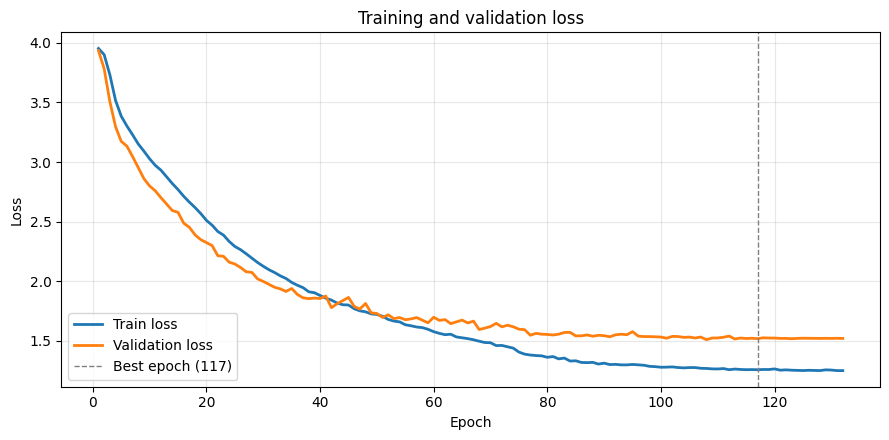

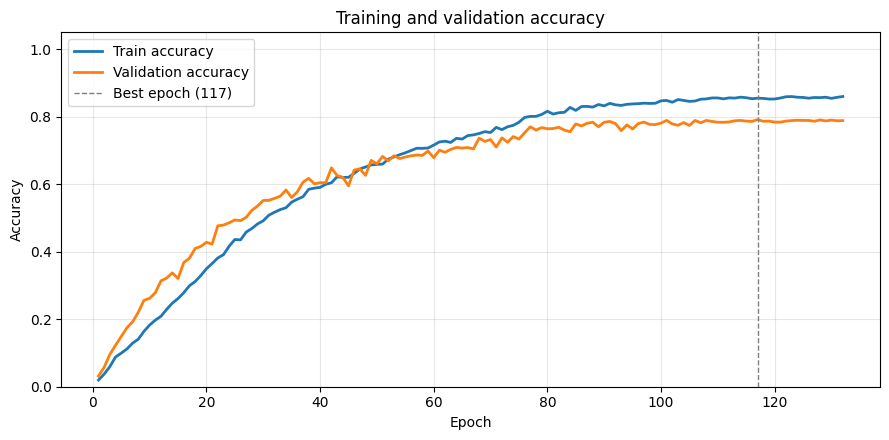

In [31]:
import matplotlib.pyplot as plt

epochs = range(1, len(history["train_loss"]) + 1)
best_ep = int(np.argmax(history["val_acc"])) + 1

# Loss curve
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(epochs, history["train_loss"], label="Train loss", linewidth=2)
ax.plot(epochs, history["val_loss"], label="Validation loss", linewidth=2)
ax.axvline(best_ep, color="gray", linestyle="--", linewidth=1, label=f"Best epoch ({best_ep})")
ax.set_xlabel("Epoch"); ax.set_ylabel("Loss")
ax.set_title("Training and validation loss")
ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "loss_curve.png"), dpi=150)
plt.show()

# Accuracy curve
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(epochs, history["train_acc"], label="Train accuracy", linewidth=2)
ax.plot(epochs, history["val_acc"], label="Validation accuracy", linewidth=2)
ax.axvline(best_ep, color="gray", linestyle="--", linewidth=1, label=f"Best epoch ({best_ep})")
ax.set_xlabel("Epoch"); ax.set_ylabel("Accuracy")
ax.set_ylim(0, 1.05)
ax.set_title("Training and validation accuracy")
ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "accuracy_curve.png"), dpi=150)
plt.show()

Test samples: 2028 | Top-1 acc: 0.7811 | Top-3 acc: 0.9300 | Macro per-class acc: 0.7811


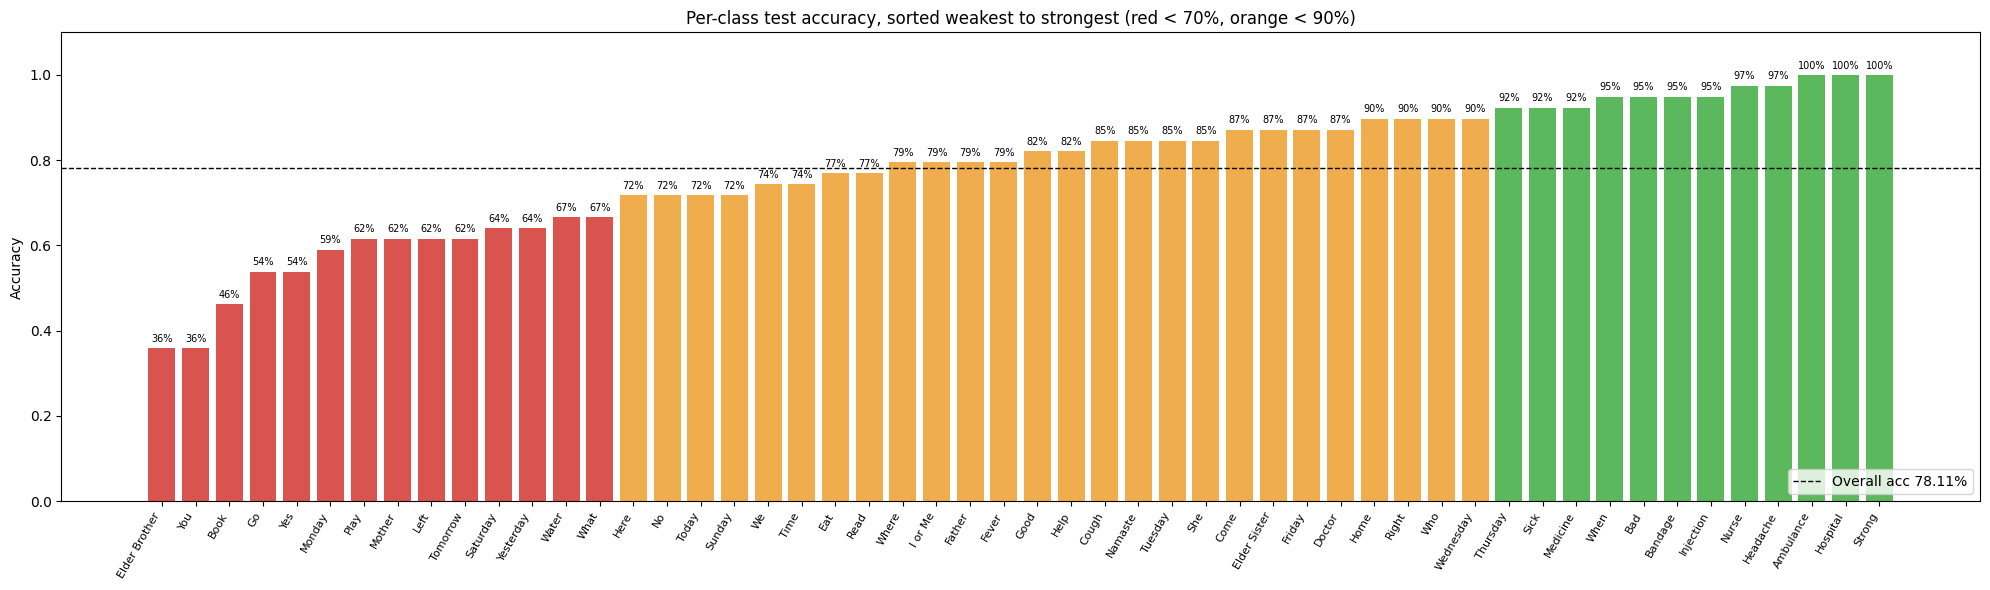

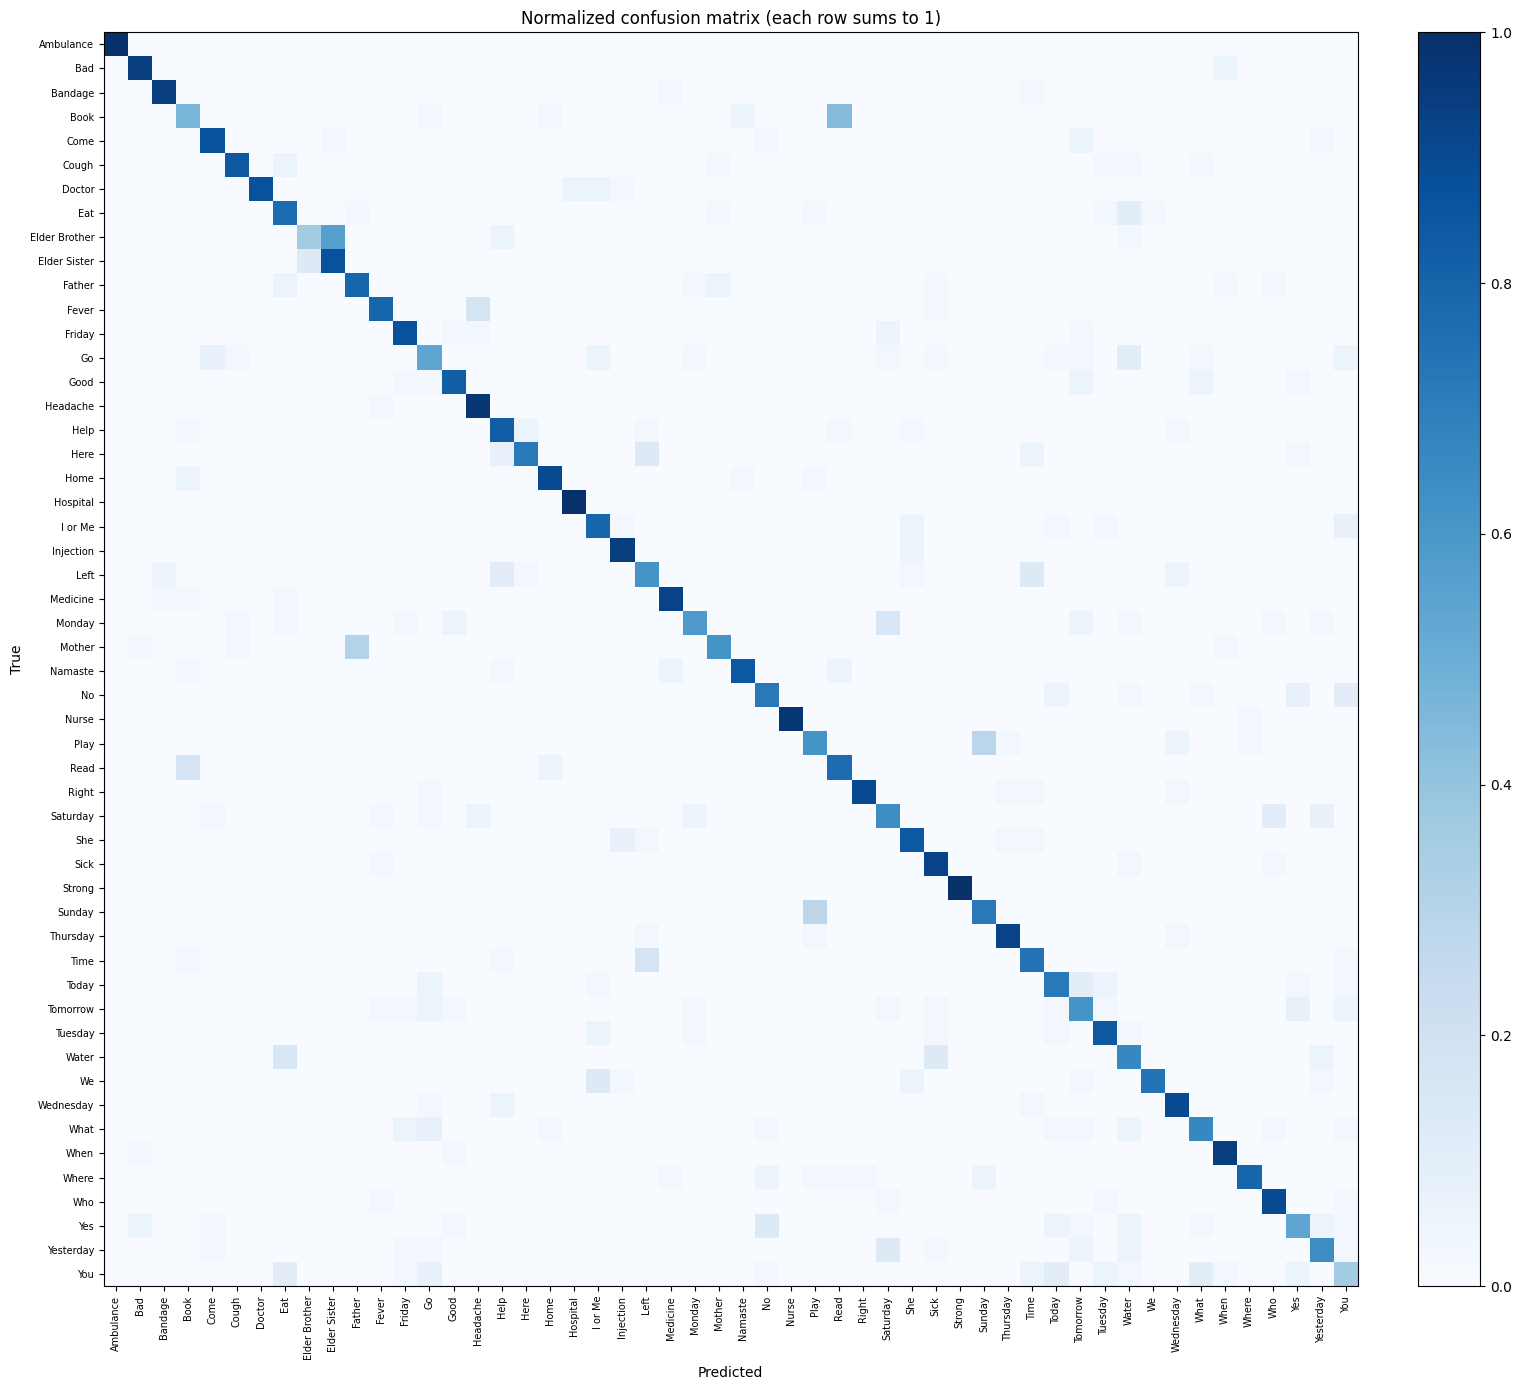

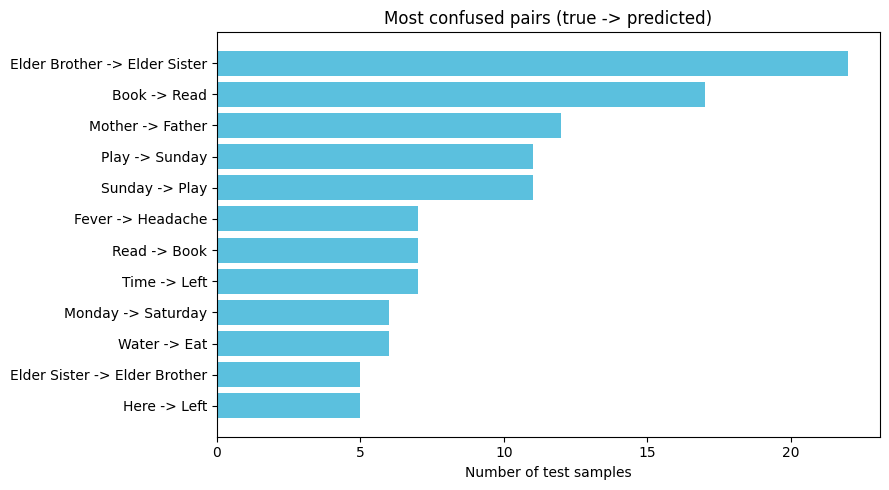

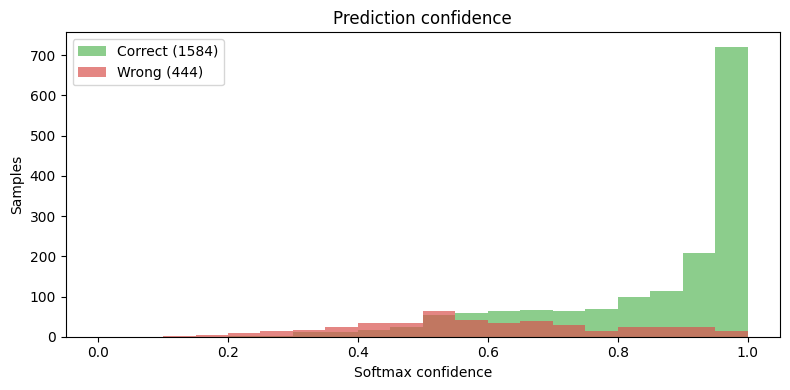

               precision    recall  f1-score   support

    Ambulance       1.00      1.00      1.00        39
          Bad       0.90      0.95      0.93        39
      Bandage       0.93      0.95      0.94        39
         Book       0.58      0.46      0.51        39
         Come       0.85      0.87      0.86        39
        Cough       0.92      0.85      0.88        39
       Doctor       1.00      0.87      0.93        39
          Eat       0.65      0.77      0.71        39
Elder Brother       0.74      0.36      0.48        39
 Elder Sister       0.60      0.87      0.71        39
       Father       0.70      0.79      0.75        39
        Fever       0.86      0.79      0.83        39
       Friday       0.83      0.87      0.85        39
           Go       0.57      0.54      0.55        39
         Good       0.84      0.82      0.83        39
     Headache       0.79      0.97      0.87        39
         Help       0.71      0.82      0.76        39
         

In [32]:
# Evaluation diagrams on the test set
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report

model.load_state_dict(torch.load(CHECKPOINT, map_location=DEVICE))
model.eval()

# Collect probabilities for every test sample
all_probs, all_labels = [], []
with torch.no_grad():
    for seqs, lengths, labels in test_loader:
        out = model(seqs.to(DEVICE), lengths.to(DEVICE))
        all_probs.append(torch.softmax(out, 1).cpu())
        all_labels.append(labels)

probs  = torch.cat(all_probs).numpy()
y_true = torch.cat(all_labels).numpy()
y_pred = probs.argmax(1)
conf   = probs.max(1)
names  = [idx_to_sign[i] for i in range(NUM_CLASSES)]

cm = confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES))
support = cm.sum(axis=1)
per_class_acc = np.divide(np.diag(cm), support, out=np.full(NUM_CLASSES, np.nan), where=support > 0)
cm_norm = np.divide(cm, support[:, None], out=np.zeros(cm.shape, dtype=float), where=support[:, None] > 0)

top3 = (np.argsort(-probs, axis=1)[:, :3] == y_true[:, None]).any(axis=1).mean()
overall = (y_pred == y_true).mean()
print(f"Test samples: {len(y_true)} | Top-1 acc: {overall:.4f} | Top-3 acc: {top3:.4f} | "
      f"Macro per-class acc: {np.nanmean(per_class_acc):.4f}")

# 1. Per-class accuracy: wide figure, classes along the x-axis
order = np.argsort(np.nan_to_num(per_class_acc, nan=-1))   # weakest on the left
vals = per_class_acc[order]
colors = ["#d9534f" if v < 0.7 else "#f0ad4e" if v < 0.9 else "#5cb85c" for v in vals]

fig, ax = plt.subplots(figsize=(20, 6))
ax.bar(range(NUM_CLASSES), vals, color=colors)
ax.axhline(overall, color="black", linestyle="--", linewidth=1, label=f"Overall acc {overall:.2%}")
ax.set_xticks(range(NUM_CLASSES))
ax.set_xticklabels([names[i] for i in order], rotation=60, ha="right", fontsize=8)
ax.set_ylim(0, 1.1)
ax.set_ylabel("Accuracy")
ax.set_title("Per-class test accuracy, sorted weakest to strongest (red < 70%, orange < 90%)")
for x, (i, v) in enumerate(zip(order, vals)):
    ax.text(x, min(v, 1.0) + 0.015, f"{v:.0%}", ha="center", fontsize=7)
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "per_class_accuracy.png"), dpi=150)
plt.show()

# 2. Normalized confusion matrix
fig, ax = plt.subplots(figsize=(16, 14))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(names, rotation=90, fontsize=7)
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(names, fontsize=7)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_title("Normalized confusion matrix (each row sums to 1)")
plt.colorbar(im, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "confusion_matrix.png"), dpi=150)
plt.show()

# 3. Most confused class pairs
off = cm.copy()
np.fill_diagonal(off, 0)
pairs = [(i, j, off[i, j]) for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if off[i, j] > 0]
pairs.sort(key=lambda p: -p[2])
pairs = pairs[:12]
if pairs:
    fig, ax = plt.subplots(figsize=(9, 5))
    labels_ = [f"{names[i]} -> {names[j]}" for i, j, _ in pairs]
    ax.barh(labels_, [c for _, _, c in pairs], color="#5bc0de")
    ax.invert_yaxis()
    ax.set_xlabel("Number of test samples")
    ax.set_title("Most confused pairs (true -> predicted)")
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, "top_confusions.png"), dpi=150)
    plt.show()

# 4. Confidence of correct vs wrong predictions (shows how usable your commit thresholds are)
fig, ax = plt.subplots(figsize=(8, 4))
correct = y_pred == y_true
ax.hist(conf[correct], bins=20, range=(0, 1), alpha=0.7, label=f"Correct ({correct.sum()})", color="#5cb85c")
ax.hist(conf[~correct], bins=20, range=(0, 1), alpha=0.7, label=f"Wrong ({(~correct).sum()})", color="#d9534f")
ax.set_xlabel("Softmax confidence"); ax.set_ylabel("Samples")
ax.set_title("Prediction confidence")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "confidence_hist.png"), dpi=150)
plt.show()

# 5. Precision / recall / F1 table
print(classification_report(y_true, y_pred, labels=range(NUM_CLASSES),
                            target_names=names, zero_division=0))

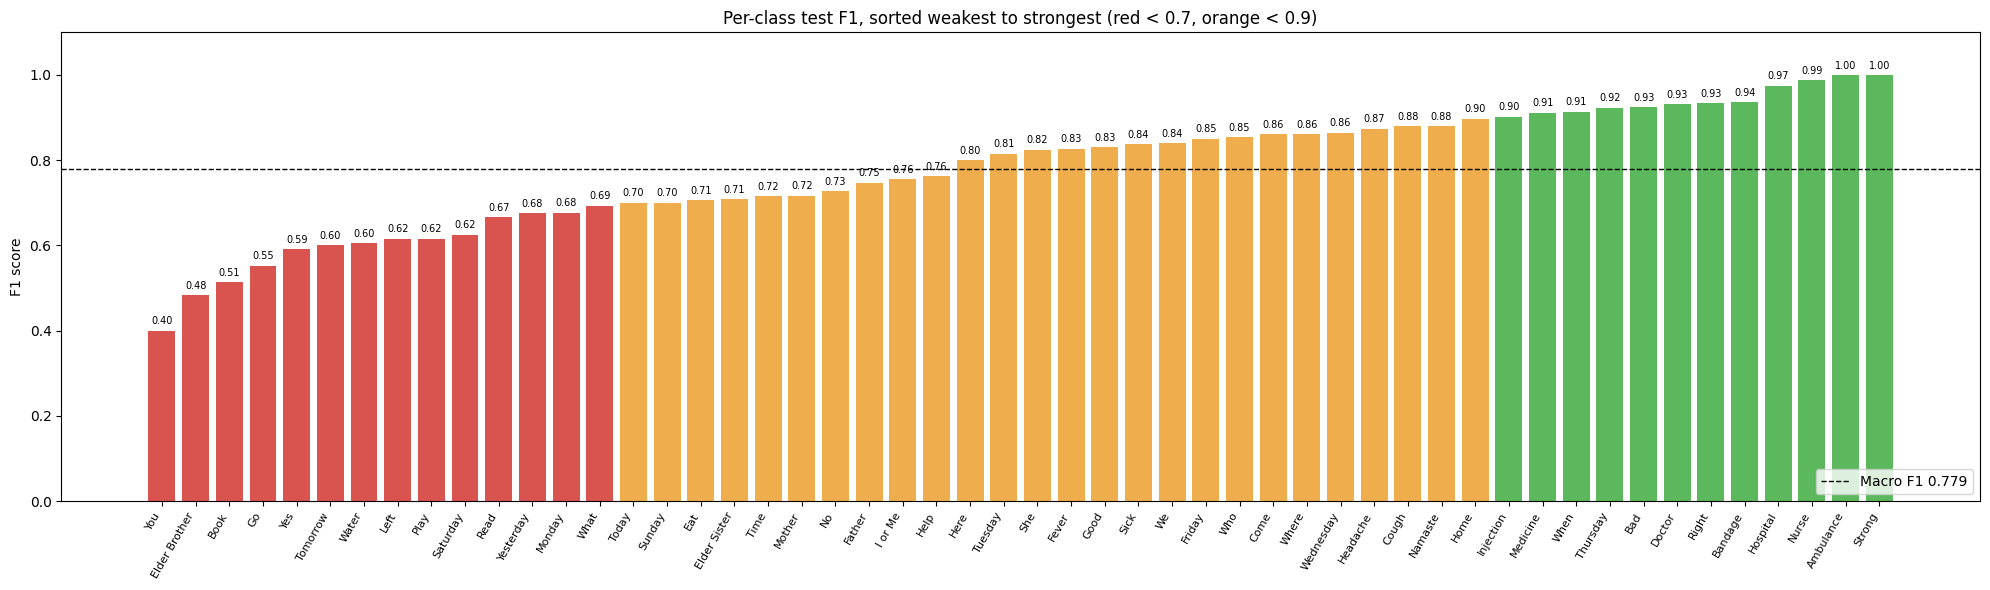

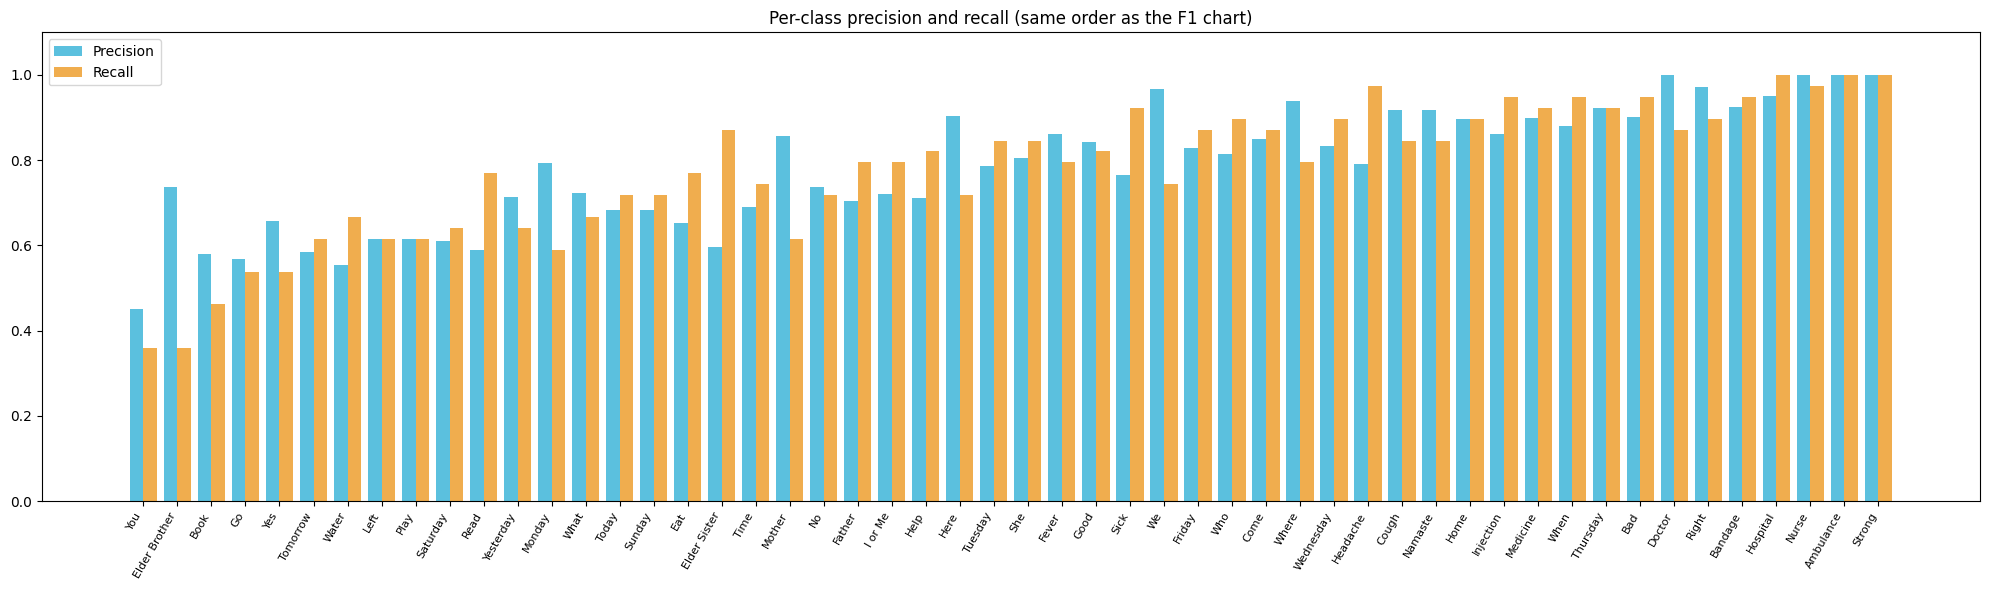

In [33]:
# Per-class F1 chart: wide figure, classes along the x-axis
from sklearn.metrics import precision_recall_fscore_support

prec, rec, f1, sup = precision_recall_fscore_support(
    y_true, y_pred, labels=range(NUM_CLASSES), zero_division=0
)
macro_f1 = f1[sup > 0].mean()

order = np.argsort(f1)   # weakest on the left
vals = f1[order]
colors = ["#d9534f" if v < 0.7 else "#f0ad4e" if v < 0.9 else "#5cb85c" for v in vals]

fig, ax = plt.subplots(figsize=(20, 6))
ax.bar(range(NUM_CLASSES), vals, color=colors)
ax.axhline(macro_f1, color="black", linestyle="--", linewidth=1, label=f"Macro F1 {macro_f1:.3f}")
ax.set_xticks(range(NUM_CLASSES))
ax.set_xticklabels([names[i] for i in order], rotation=60, ha="right", fontsize=8)
ax.set_ylim(0, 1.1)
ax.set_ylabel("F1 score")
ax.set_title("Per-class test F1, sorted weakest to strongest (red < 0.7, orange < 0.9)")
for x, v in enumerate(vals):
    ax.text(x, min(v, 1.0) + 0.015, f"{v:.2f}", ha="center", fontsize=7)
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "per_class_f1.png"), dpi=150)
plt.show()

# Optional: precision vs recall per class, to see why a class has a low F1
x = np.arange(NUM_CLASSES)
fig, ax = plt.subplots(figsize=(20, 6))
ax.bar(x - 0.2, prec[order], width=0.4, label="Precision", color="#5bc0de")
ax.bar(x + 0.2, rec[order], width=0.4, label="Recall", color="#f0ad4e")
ax.set_xticks(x)
ax.set_xticklabels([names[i] for i in order], rotation=60, ha="right", fontsize=8)
ax.set_ylim(0, 1.1)
ax.set_title("Per-class precision and recall (same order as the F1 chart)")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "per_class_precision_recall.png"), dpi=150)
plt.show()

# Save the numbers too
import pandas as pd
pd.DataFrame({"class": names, "precision": prec, "recall": rec, "f1": f1, "test_samples": sup}) \
  .sort_values("f1").to_csv(os.path.join(OUT_DIR, "per_class_f1.csv"), index=False)

test: 2028 embeddings of dimension 160


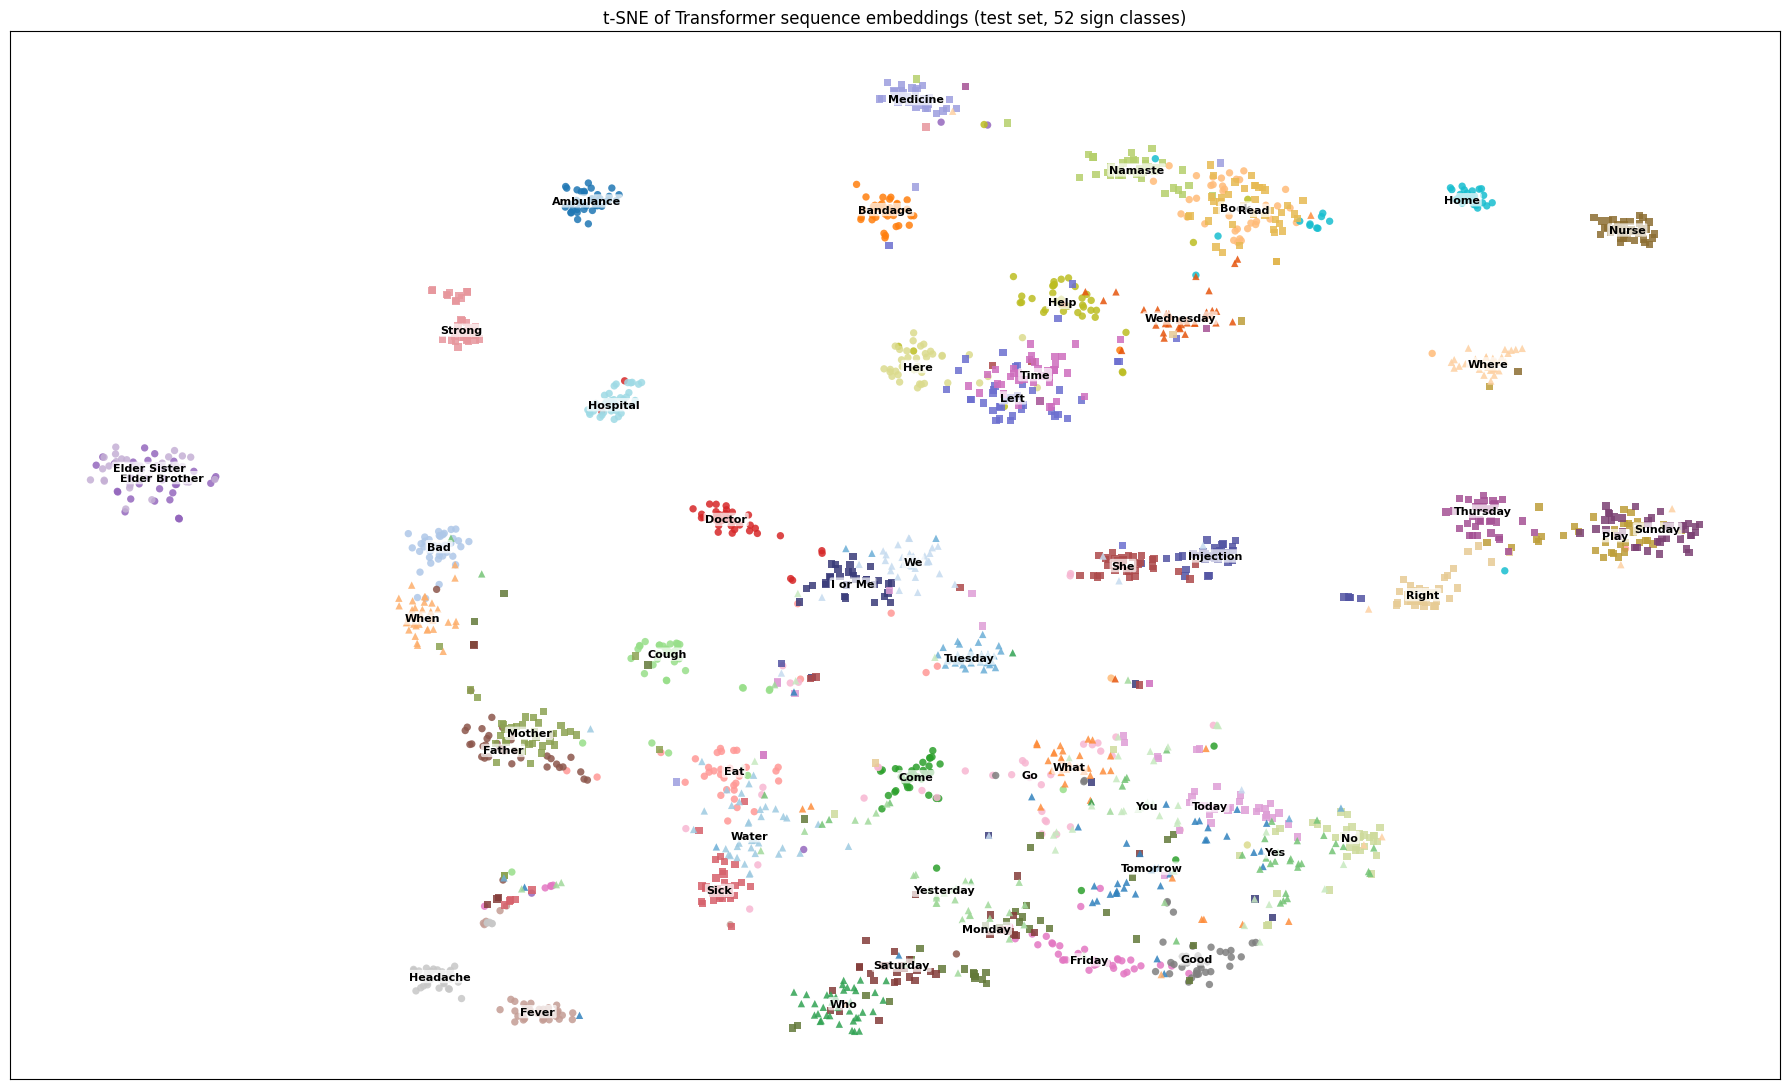

Silhouette score (original 160-d embeddings): 0.165


In [34]:
# t-SNE of Transformer sequence embeddings (52 classes)
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score

SPLIT = "test"   # "test", "val" or "train"

loader_map = {"test": test_loader, "val": val_loader}
if SPLIT == "train":
    # Plain loader with augmentation switched off, so embeddings reflect the real clips
    train_dataset.train = False
    loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=False)
else:
    loader = loader_map[SPLIT]

model.load_state_dict(torch.load(CHECKPOINT, map_location=DEVICE))
model.eval()

# Capture the pooled vector that goes into the classifier
captured = []
hook = model.classifier.register_forward_pre_hook(lambda m, inp: captured.append(inp[0].detach().cpu()))

labels_list = []
with torch.no_grad():
    for seqs, lengths, labels in loader:
        model(seqs.to(DEVICE), lengths.to(DEVICE))
        labels_list.append(labels)
hook.remove()
if SPLIT == "train":
    train_dataset.train = True   # restore

emb = torch.cat(captured).numpy()
y = torch.cat(labels_list).numpy()
print(f"{SPLIT}: {emb.shape[0]} embeddings of dimension {emb.shape[1]}")

# Run t-SNE
perplexity = min(30, max(5, (len(emb) - 1) // 3))
xy = TSNE(n_components=2, perplexity=perplexity, init="pca",
          learning_rate="auto", random_state=SEED).fit_transform(emb)

# 52 distinguishable colors: three qualitative palettes, plus a marker per group of 20
palette = np.vstack([cm.tab20(np.arange(20)), cm.tab20b(np.arange(20)), cm.tab20c(np.arange(20))])
markers = ["o", "s", "^"]

fig, ax = plt.subplots(figsize=(18, 11))
for c in range(NUM_CLASSES):
    m = y == c
    if m.any():
        ax.scatter(xy[m, 0], xy[m, 1], s=28, color=palette[c], marker=markers[c // 20],
                   alpha=0.85, edgecolors="none")
        cx, cy = np.median(xy[m, 0]), np.median(xy[m, 1])
        ax.text(cx, cy, idx_to_sign[c], fontsize=8, weight="bold", ha="center", va="center",
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.7))

ax.set_title(f"t-SNE of Transformer sequence embeddings ({SPLIT} set, {NUM_CLASSES} sign classes)")
ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, f"tsne_embeddings_{SPLIT}.png"), dpi=200)
plt.show()

# Numeric cluster quality: higher means classes are better separated (range -1 to 1)
print(f"Silhouette score (original 160-d embeddings): {silhouette_score(emb, y):.3f}")

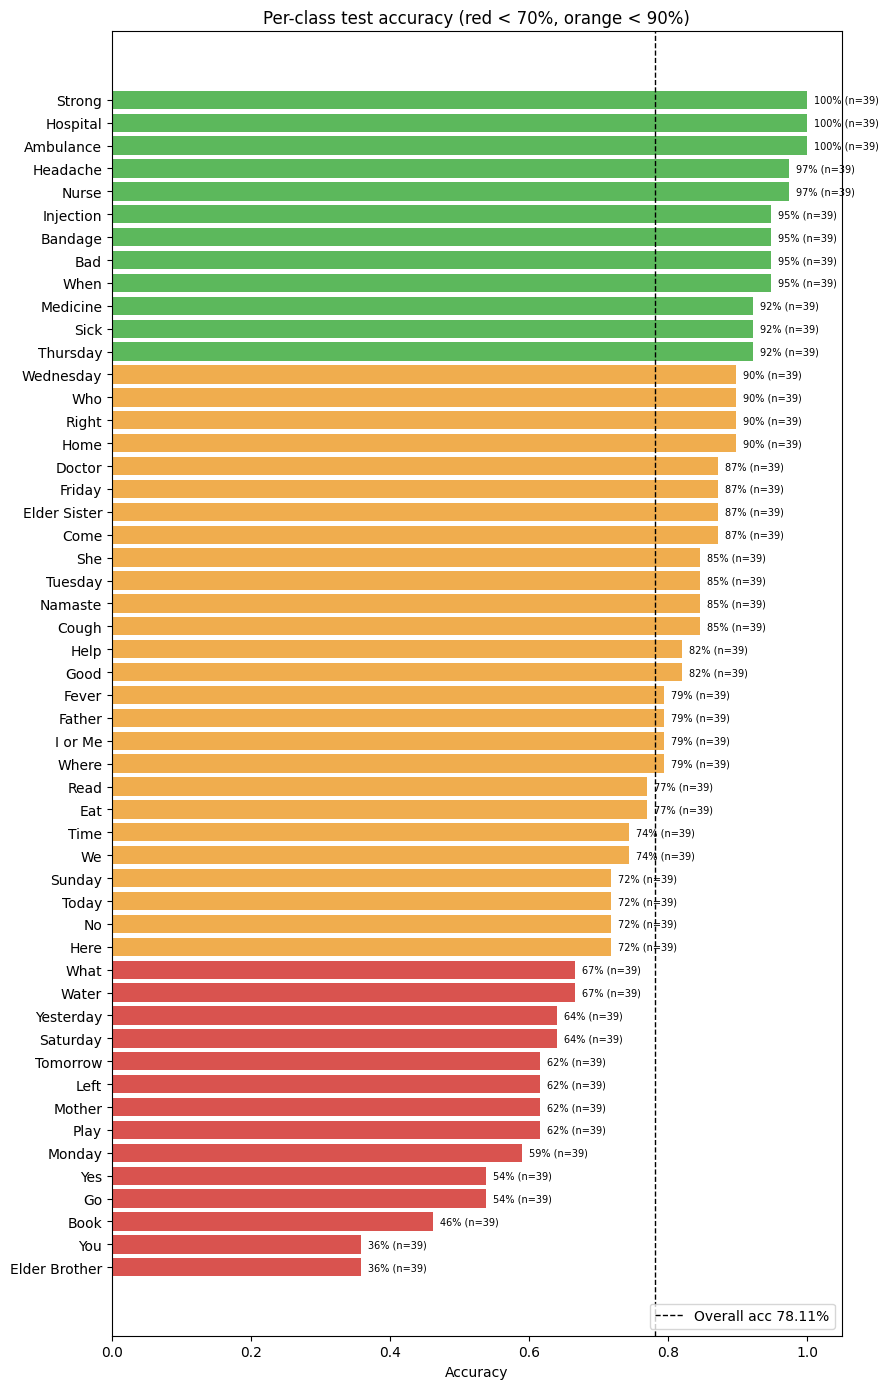

In [35]:
# 1. Per-class accuracy bar chart (sorted, worst at the bottom)
order = np.argsort(np.nan_to_num(per_class_acc, nan=-1))[::-1]
fig, ax = plt.subplots(figsize=(9, 14))
vals = per_class_acc[order]
colors = ["#d9534f" if v < 0.7 else "#f0ad4e" if v < 0.9 else "#5cb85c" for v in vals]
ax.barh([names[i] for i in order], vals, color=colors)
ax.axvline(overall, color="black", linestyle="--", linewidth=1, label=f"Overall acc {overall:.2%}")
ax.set_xlim(0, 1.05)
ax.set_xlabel("Accuracy")
ax.set_title("Per-class test accuracy (red < 70%, orange < 90%)")
ax.invert_yaxis()
for y, (i, v) in enumerate(zip(order, vals)):
    ax.text(min(v, 1.0) + 0.01, y, f"{v:.0%} (n={support[i]})", va="center", fontsize=7)
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "per_class_accuracy_vertical.png"), dpi=150)
plt.show()

## After training

Download `best_model2.pth` and `class_mapping.json` from the `colab_output` folder in Drive and place them at:

- `models/gesture_transformer/best/best_model2.pth`
- `data/metadata/class_mapping.json`

`predictor.py` loads this checkpoint format directly.

**Comparing runs:** run once with `USE_AUG_FILES = False` and once with `True` (change the output folder name between runs so you don't overwrite), then compare the test accuracy and weakest-10 list.